# Week 7a.1: Parallelization

So far, we've mainly focused on single-agent systems, where a single agent decided what tools to call, executed them, and acted on the results from those tool calls.

Today we'll dive into multi-agent systems.

<img src="figures/parallel_search.png" width="860">

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()
assert os.getenv("GOOGLE_API_KEY"), "No GOOGLE_API_KEY found."
assert os.getenv("TAVILY_API_KEY"), "No TAVILY_API_KEY found."
print("API keys loaded")

API keys loaded


## 0. Model Setup

Execute one of the following to define the model.

In [2]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:9b", reasoning=False)

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-4.1-mini")

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

## 1. Two search tools

We'll use two sources that are good at different things. 
- Tavily, the web search API from Week 2, is good for what is current and what practitioners are saying. 
- Wikipedia is good for definitions, history, and who did what. Wikipedia has a public search API that needs no key, so we'll call it directly with `requests`.


In [3]:
import time
import requests
from langchain_tavily import TavilySearch

clock = []           # (event, seconds since the run started), filled in by the tools
run_started = 0.0


def stamp(event):
    clock.append((event, time.time() - run_started))


def search_web(query: str) -> str:
    """Search the web. Returns the top results as title, URL, and a snippet."""
    stamp("web search started")
    results = TavilySearch(max_results=3).invoke({"query": query})["results"]
    stamp("web search finished")
    return "\n\n".join(f"{r['title']}\n{r['url']}\n{r['content'][:400]}" for r in results)

In [4]:
WIKI = "https://en.wikipedia.org/w/api.php"
HEADERS = {"User-Agent": "CS6983_AAI_oio2i3223o2i4o3i4"}   # Wikipedia refuses anonymous clients


def wiki_get(**params):
    """One call to the Wikipedia API. Now and then Wikipedia answers a burst of
    requests with an HTML error page instead of JSON, so we check before parsing."""
    r = requests.get(WIKI, params={**params, "format": "json"}, headers=HEADERS, timeout=10)
    if r.status_code != 200 or "json" not in r.headers.get("content-type", ""):
        raise RuntimeError(f"Wikipedia answered HTTP {r.status_code}")
    return r.json()


def search_wikipedia(query: str) -> str:
    """Search Wikipedia. Returns the opening paragraph of the top three articles."""
    stamp("wikipedia search started")
    try:
        hits = wiki_get(action="query", list="search", srsearch=query, srlimit=3)
        titles = [h["title"] for h in hits["query"]["search"]]
        pages = wiki_get(action="query", prop="extracts", exintro=1, explaintext=1, titles="|".join(titles))
    except RuntimeError as e:
        stamp("wikipedia search failed")
        return f"No Wikipedia results: {e}"
    stamp("wikipedia search finished")
    return "\n\n".join(f"{p['title']}\n{p.get('extract', '')[:600]}" for p in pages["query"]["pages"].values())

In [5]:
print(search_web("What is the transformer architecture, and who proposed it?")[:600], "...")


Transformer (deep learning) - Wikipedia
https://en.wikipedia.org/wiki/Transformer_(deep_learning)
The original version of the transformer architecture was proposed in the 2017 paper "Attention Is All You Need" by researchers at Google.( The predecessors of transformers were developed as an improvement over previous architectures for machine translation,( but have found many applications since. They are used in large-scale natural language processing, computer vision (vision transformers), rein

What is a Transformer Model? | IBM
https://www.ibm.com/think/topics/transformer-model
The transforme ...


In [6]:
print(search_wikipedia("What is the transformer architecture, and who proposed it?")[:600], "...")

Attention Is All You Need
"Attention Is All You Need" is a 2017 research paper on machine learning authored by eight scientists and engineers working at Google. The paper introduced a new deep learning architecture known as the transformer, based on the attention mechanism proposed in 2014 by Bahdanau et al. The transformer approach it describes has become the main architecture of a wide variety of artificial intelligence systems, including large language models. At the time, the focus of the research was on improving Seq2seq techniques for machine translation, but the authors went further in  ...


## 2. A single agent with both tools

A ReAct agent to do this:

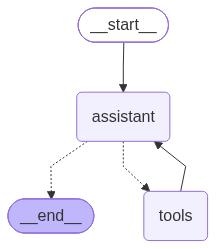

In [7]:
from langchain.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display

TOOLS = [search_web, search_wikipedia]
model_with_tools = model.bind_tools(TOOLS)

SINGLE_PROMPT = """You are a research assistant. Never answer from memory. For every question,
first call search_web and search_wikipedia, read what they return, and only
then write one short paragraph that says which source each fact came from and
points out anything the two sources disagree on."""


def assistant(state: MessagesState) -> dict:
    return {"messages": [model_with_tools.invoke([SystemMessage(content=SINGLE_PROMPT)] + state["messages"])]}


g = StateGraph(MessagesState)
g.add_node("assistant", assistant)
g.add_node("tools", ToolNode(TOOLS))
g.add_edge(START, "assistant")
g.add_conditional_edges("assistant", tools_condition)
g.add_edge("tools", "assistant")
single = g.compile()
display(Image(single.get_graph().draw_mermaid_png()))

In [8]:
# new question due to Tavily cache
QUESTION = "What is retrieval-augmented generation, and who introduced it?"

clock.clear()
run_started = time.time()
result = single.invoke({"messages": [HumanMessage(content=QUESTION)]})
single_total = time.time() - run_started

print(result["messages"][-1].text)
print()
for event, seconds in clock:
    print(f"  {seconds:5.1f} s  {event}")
model_calls = sum(1 for m in result["messages"] if m.type == "ai")
print(f"  {single_total:5.1f} s  done, after {model_calls} model calls")

Retrieval-Augmented Generation (RAG) is a technique that enables large language models to retrieve and incorporate new information from external data sources during inference, combining parametric model knowledge with non-parametric external memory accessed at query time. This allows models to use domain-specific or up-to-date information not present in their training data. The term "Retrieval-Augmented Generation" was formally introduced by Dr. Patrick Lewis and colleagues in a 2020 paper titled "Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks."

   10.7 s  web search started
   10.7 s  wikipedia search started
   11.4 s  wikipedia search finished
   12.3 s  web search finished
   23.3 s  done, after 2 model calls


Two things to control:
- The searches should start right away, without a model call in front of them. 
- Both sources should be consulted every time, because we decided that, not the model.
    - Currently, the decision is up to the agent (sometimes both tools, sometimes one)

## 3. Parallelization
Concurrent execution of nodes:
- Allows multiple nodes to execute concurrently during a single execution phase
- Reduces overall latency for **independent** tasks

Two types of parallelization:
- **Static parallelization (fan-out)**: Parallel nodes are defined by connecting a single node to multiple others, all of which run concurrently
    - Use when you know exactly which nodes need to run in parallel
- **Dynamic fan-out**: Concurrent workers are spawned at runtime (through SEND API)
    - Use when the number of parallel tasks cannot be determined ahead of time

In [ ]:
from typing import TypedDict


class SearchState(TypedDict):
    question: str
    web: str
    wiki: str
    answer: str

def web_node(state: SearchState) -> dict:
    return {"web": search_web(state["question"])}


def wiki_node(state: SearchState) -> dict:
    return {"wiki": search_wikipedia(state["question"])}


SYNTH_PROMPT = """Question: {question}

Web search results:
{web}

Wikipedia:
{wiki}

Answer the question in one short paragraph from these two sources. Say which
source each fact came from, and point out anything the two sources disagree on."""


def synthesize(state: SearchState) -> dict:
    out = model.invoke(SYNTH_PROMPT.format(**state))
    return {"answer": out.text}

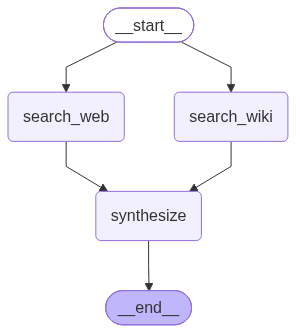

In [10]:
p = StateGraph(SearchState)

p.add_node("search_web", web_node)
p.add_node("search_wiki", wiki_node)
p.add_node("synthesize", synthesize)

#TODO: Add edges (5)
p.add_edge(START, "search_web")
p.add_edge(START, "search_wiki")
p.add_edge("search_web", "synthesize")
p.add_edge("search_wiki", "synthesize")
p.add_edge("synthesize", END)



parallel = p.compile()

display(Image(parallel.get_graph().draw_mermaid_png()))

In [11]:
QUESTION_2 = "What is reinforcement learning from human feedback, and where was it first used?"

clock.clear()
run_started = time.time()

result = parallel.invoke({"question": QUESTION_2})
parallel_total = time.time() - run_started

print(result["answer"])
print()

for event, seconds in clock:
    print(f"  {seconds:5.1f} s  {event}")
print(f"  {parallel_total:5.1f} s  done, after 1 model call")

Reinforcement learning from human feedback (RLHF) is a machine learning technique used to align an intelligent agent with human preferences by first training a reward model based on direct human evaluations of model responses, which is then used to optimize the agent's policy via reinforcement learning; this definition is supported by both AWS and IBM sources, while Wikipedia adds context that RLHF involves representing these preferences to guide future behavior. Neither source presents a factual disagreement regarding the core definition or origin of the technique in their provided excerpts; however, the Wikipedia snippet notably clarifies that RLHF was not the first method ever used for human feedback in reinforcement learning, though it remains a prominent modern approach alongside traditional supervised and unsupervised learning paradigms mentioned by AWS.

    0.0 s  web search started
    0.0 s  wikipedia search started
    0.1 s  web search finished
    0.9 s  wikipedia search f

NOTE: 

Each branch wrote to its own key in the state, `web` and `wiki`. 

If both had written to the same key, LangGraph would have refused to run the graph, because it would not know which value to keep.

## 4. Multi-Agent Collaboration

In multi-agent collaboration, the agents read from and write to the same scratchpad.

To enable multiple agents to modify the state schema, we'll use a reducer and replace `web` and `wiki` with one list called `findings`.


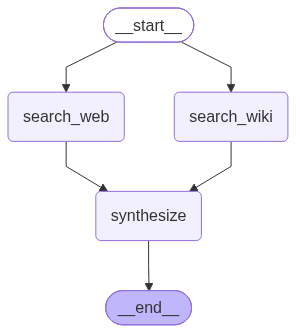

In [12]:
import operator
from typing import Annotated


class FindingsState(TypedDict):
    question: str
    findings: Annotated[list, operator.add]     # each branch appends one (source, text) pair
    answer: str


def web_branch(state: FindingsState) -> dict:
    return {"findings": [("web", search_web(state["question"]))]}


def wiki_branch(state: FindingsState) -> dict:
    return {"findings": [("wikipedia", search_wikipedia(state["question"]))]}


SYNTH_PROMPT_2 = """Question: {question}

{findings}

Answer the question in one short paragraph from these sources. Say which
source each fact came from, and point out anything the sources disagree on."""


def synthesize_findings(state: FindingsState) -> dict:
    findings = "\n\n".join(f"Source: {name}\n{text}" for name, text in state["findings"])
    out = model.invoke(SYNTH_PROMPT_2.format(question=state["question"], findings=findings))
    return {"answer": out.text}


f = StateGraph(FindingsState)
f.add_node("search_web", web_branch)
f.add_node("search_wiki", wiki_branch)
f.add_node("synthesize", synthesize_findings)
f.add_edge(START, "search_web")
f.add_edge(START, "search_wiki")
f.add_edge("search_web", "synthesize")
f.add_edge("search_wiki", "synthesize")
f.add_edge("synthesize", END)

parallel2 = f.compile()

display(Image(parallel2.get_graph().draw_mermaid_png()))

In [13]:
result = parallel2.invoke({"question": QUESTION, "findings": [], "answer": ""})
print("sources in the list:", [name for name, _ in result["findings"]])
print()
print(result["answer"])

sources in the list: ['web', 'wikipedia']

Retrieval-Augmented Generation (RAG) is a technique that enhances large language models by connecting them with external knowledge bases or non-parametric memory to improve response accuracy and reliability using information retrieved at inference time. This approach was introduced in 2020 by a research team led by Douwe Kiela at Meta AI, as confirmed by sources citing Wikipedia regarding the introduction date and authorship, and IBM/NVIDIA descriptions of the architecture's function. Based on the provided texts, there is no disagreement between the sources; they consistently define RAG similarly and attribute its 2020 introduction to Meta AI (noting Douwe Kiela's prior leadership role there), even though other sections mention his current or past roles at Google DeepMind and Contextual AI.


## 5. Common Multi-Agent Patterns

| shape | who decides the branches | when to use it |
|---|---|---|
| **Parallel branches** | we do, in code: fixed nodes, fixed edges | the sources are known before the task is read |
| **Dynamic workers** | a planner, at run time: one worker per sub-question it writes | the parts of the task are not known until the task is read |
| **Orchestration** | the agents themselves, or a supervisor: roles that hand work to each other | the work has stages, and each stage depends on what came before |

Each shape costs more to coordinate than the one above it. Fixed branches cost nothing, because there is no decision. Dynamic workers cost a planning call. Orchestration costs a decision at every handoff. The rule we'll follow this week is to start with the cheapest shape that fits the task and move down the table only when the task forces us to.

## 6. Things to try

1 Make one branch fail. Give `search_wikipedia` a query that returns nothing, or disconnect from the network for that branch. What does the graph do? Then change the branch so that a failure returns an empty finding, and see what the synthesizer does with it.

2. The synthesizer is told to point out disagreements. Ask a question where the two sources are likely to disagree, for example about something that happened this year, and read what it does with the conflict.

3. Rewrite `SINGLE_PROMPT` in section 2 so that the agent is told to search one source at a time, read the result, and then search the other. Time it again and compare the timestamps with the parallel graph's.

In [ ]:
# your experiments here